# Real-data dual-channel analysis

Load one SIF and a saved calibration bundle, reconstruct its ROI, then create a registered `MultiImageStack`. Registration is attached as coordinate metadata; image pixels are not warped.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from smlm.camera import EMCCD
from smlm.io import load_raw
from smlm.localize import localize_stack
from smlm.multiplex import (
    multichannel_stack_from_calibration,
    plot_multichannel_crop,
    plot_multichannel_localizations,
)

In [2]:
DATA_FILE = Path(r"G:\PacBio\近观DNA_FRET\20261123\sample32_532nm_2mW_0p1S_2000frames_fov6.sif")
CALIBRATION_FILE = Path(r"G:\PacBio\近观DNA_FRET\20261123\std1_multichannel_calibration.npz")

for path in (DATA_FILE, CALIBRATION_FILE):
    if not path.is_file():
        raise FileNotFoundError(path)

In [3]:
raw = load_raw(DATA_FILE)
raw.metadata.pop("imageData", None)
camera = EMCCD(conv_factor=5.75, em_gain=300)
image = camera.process(raw, pixel_size=106.6)
EXPOSURE_S = raw.exposure_time
del raw

{"image_shape_T_HW": image.shape, "pixel_size_nm": image.pixel_size,
 "exposure_s": EXPOSURE_S}

{'image_shape_T_HW': (2000, 512, 512),
 'pixel_size_nm': 106.6,
 'exposure_s': 0.1}

In [4]:
from smlm.imgprocess import Pipeline, Crop, SelectFrames
prep = Pipeline(Crop(y=(0, 512), x=(0,512)),
                SelectFrames(start=0,stop=2000))
stack = prep(image)
stack.shape

(2000, 512, 512)

<Axes: title={'center': 'frame 0'}, xlabel='x (px)', ylabel='y (px)'>

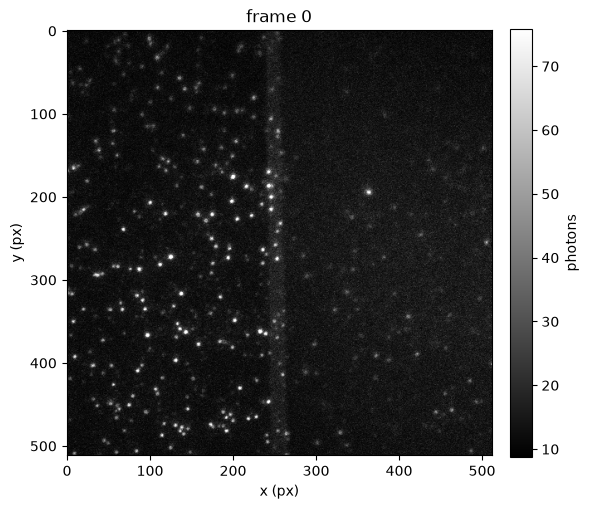

In [5]:
from smlm.viz import show_frames
show_frames(stack, frames=0)

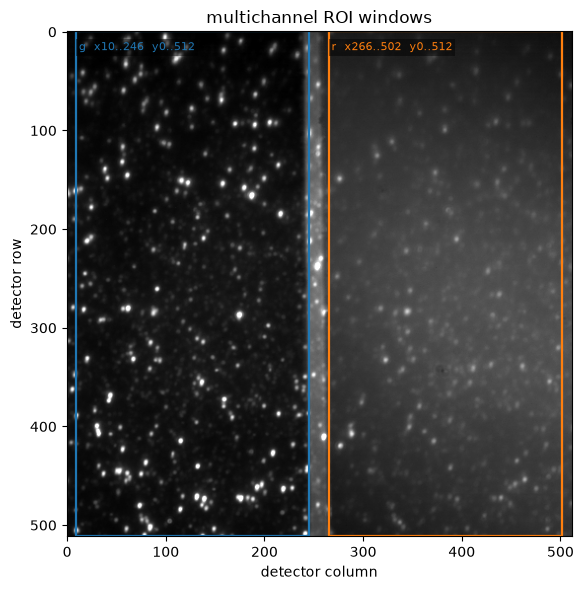

In [6]:
multiStack = multichannel_stack_from_calibration(
    stack, CALIBRATION_FILE, show_roi=True)

## Choose the analysis window

Trim the matched calibration ROI independently at the top, bottom, left, and right. The values and resulting range are in the shared local coordinates of `multi`. Preview the same window on adjacent channel images, then crop with `MultiImageStack.crop()`; channel detector origins advance together with the crop start while `reg` remains attached.

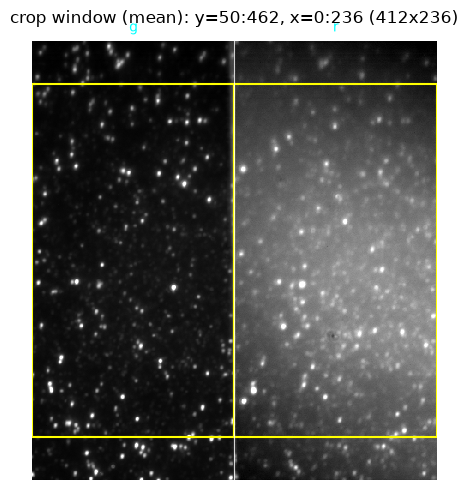

In [7]:
# Additional crop from the calibration ROI, in pixels on each side.
from smlm.multiplex import plot_multichannel_crop
TRIM_TOP = 50
TRIM_BOTTOM = 50
TRIM_LEFT = 0
TRIM_RIGHT = 0
trims = (TRIM_TOP, TRIM_BOTTOM, TRIM_LEFT, TRIM_RIGHT)
if any(not isinstance(value, int) or value < 0 for value in trims):
    raise ValueError("All four trims must be non-negative integers")

_, _, MULTI_HEIGHT, MULTI_WIDTH = multiStack.shape
ANALYSIS_Y = (TRIM_TOP, MULTI_HEIGHT - TRIM_BOTTOM)
ANALYSIS_X = (TRIM_LEFT, MULTI_WIDTH - TRIM_RIGHT)
if ANALYSIS_Y[1] <= ANALYSIS_Y[0] or ANALYSIS_X[1] <= ANALYSIS_X[0]:
    raise ValueError("Trims leave an empty analysis window")

fig = plot_multichannel_crop(multiStack, y=ANALYSIS_Y, x=ANALYSIS_X)
plt.show()

In [8]:
multiStackAnalysis = multiStack.crop(y=ANALYSIS_Y, x=ANALYSIS_X)
print(multiStackAnalysis)
multiStackAnalysis.geometry(check_coverage=False).report()

MultiImageStack(C=2, T=2000, H=412, W=236, channels=['g', 'r'], ref='g')
  reference = 'g', channels = ['g', 'r'], 配准到参考: ['r']
  g: 分析窗口 detector y50..462 x10..246  (412x236)  <- 参考
      标定窗口 y0 x10  ->  分析坐标 + (+0, +50) = 标定坐标
  r: 分析窗口 detector y50..462 x266..502  (412x236)
      标定窗口 y0 x266  ->  分析坐标 + (+0, +50) = 标定坐标
  calib[r]: order 1, coarse_offset (0.0, 256.0), coverage x[20.05143965631172, 227.83185935842533] y[81.85776772736013, 476.8646442488671]
  公共可用区(参考分析坐标): x 0.0~235.7, y 0.0~411.9
  [!] 分析窗口比标定点覆盖大 31.9 px; 当前是 order 1(仿射), 外推精确, 可忽略。   r 超出 x 20.1 / y 31.9 px


<string>:12: RuntimeWarning: 分析窗口比标定点覆盖大 31.9 px; 当前是 order 1(仿射), 外推精确, 可忽略。   r 超出 x 20.1 / y 31.9 px


## Detect and localize each channel
 
 `multiLocs` maps each channel name to its localizations. Coordinates remain local to each cropped channel; the updated detector origins are retained in the stack.


In [10]:
# Explicit cache mode:
# False = run detection/localization and overwrite the cache.
# True  = load the existing cache; missing or incompatible caches raise an error.
READ_LOC_CACHE = True
LOC_CACHE_DIR = DATA_FILE.parent / "localization_cache"
if READ_LOC_CACHE and not LOC_CACHE_DIR.is_dir():
    raise FileNotFoundError(f"Localization cache directory not found: {LOC_CACHE_DIR}")
LOC_CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Sample settings mirrored from test_process_dual.
K_SIGMA = {"g": 2.0, "r": 1.4}
DET_KW = dict(edge=5, f_em=np.sqrt(2), bg_window=15,
              max_size=7, min_neighbors=2)
LOC_KW = dict(edge=5, F_EM=np.sqrt(2), use_pixel=False,
              use_gradient=True, n_jobs=14, verbose=False)
FILT_KW = dict(photons=(3, 1e7), bg=(0, 1e5), sigma=(0.7, 4.0), lp=None)

multiLocs = {}
for channel in multiStackAnalysis.channels:
    channel_stack = multiStackAnalysis.channel(channel)
    cache_base = LOC_CACHE_DIR / f"{DATA_FILE.stem}_{channel}"
    locs = localize_stack(
        channel_stack,
        k_sigma=K_SIGMA.get(channel, 1.5),
        det_kw=DET_KW,
        loc_kw=LOC_KW,
        filt_kw=FILT_KW,
        src_path=cache_base,
        read_cache=READ_LOC_CACHE,
        verbose=True,
        tag=channel,
    )
    multiLocs[channel] = locs

[
    {"channel": channel, "n_localizations": len(locs),
     "per_frame": len(locs) / multiStackAnalysis.n_frames,
     "origin_yx": multiStackAnalysis.channel_offset(channel)}
    for channel, locs in multiLocs.items()
]

[cache] loaded 159069 filtered locs -> G:\PacBio\近观DNA_FRET\20261123\localization_cache\sample32_532nm_2mW_0p1S_2000frames_fov6_g.locs.npz
  cached localization parameters are in cache metadata
[cache] loaded 44431 filtered locs -> G:\PacBio\近观DNA_FRET\20261123\localization_cache\sample32_532nm_2mW_0p1S_2000frames_fov6_r.locs.npz
  cached localization parameters are in cache metadata


[{'channel': 'g',
  'n_localizations': 159069,
  'per_frame': 79.5345,
  'origin_yx': (50, 10)},
 {'channel': 'r',
  'n_localizations': 44431,
  'per_frame': 22.2155,
  'origin_yx': (50, 266)}]

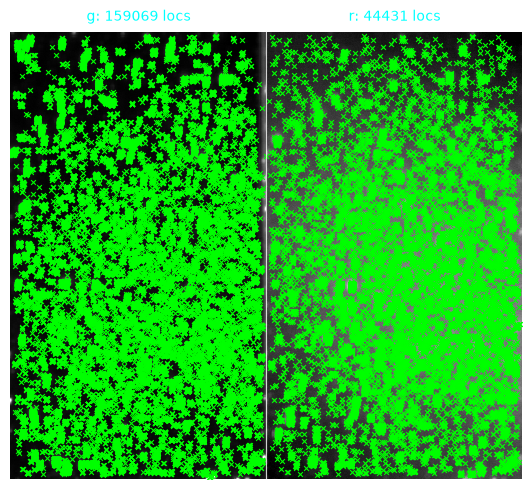

In [11]:
fig = plot_multichannel_localizations(multiStackAnalysis, multiLocs)
plt.show()

## Estimate multichannel drift

Drift is estimated from the selected channels and converted to every channel. The outlined area is the region shared by all frames; the labels give the minimum pixels lost on each side.

<string>:12: RuntimeWarning: 分析窗口比标定点覆盖大 31.9 px; 当前是 order 1(仿射), 外推精确, 可忽略。   r 超出 x 20.1 / y 31.9 px


  merged registered cloud: 203500 localizations (g:159069, r:44431) in 'g' coordinates
  estimated 'g' drift: 5.83 px from ['g', 'r']
  converted drift to channels: g:5.83px, r:5.82px


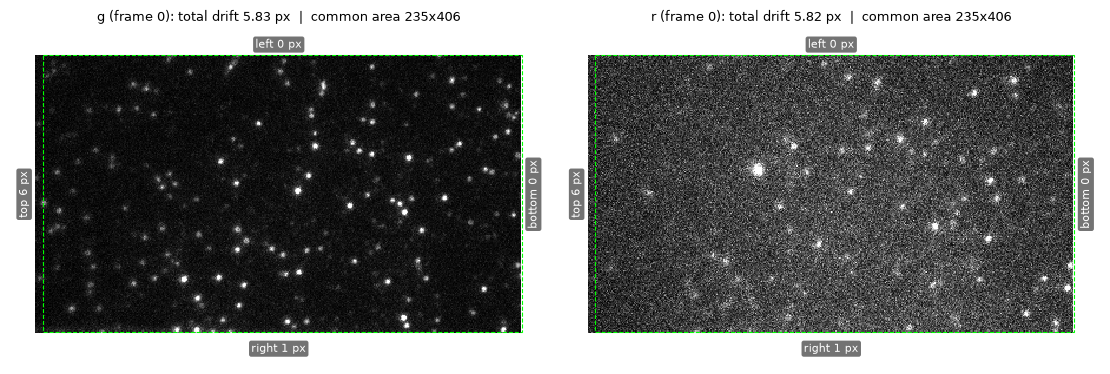

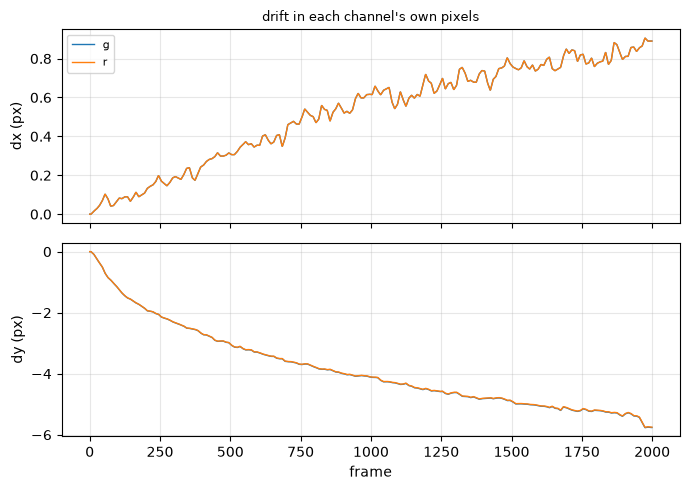

In [12]:
import smlm.multiplex as mp

COORD_REFERENCE = multiStackAnalysis.ref_name   # registration/coordinate reference
DRIFT_REFERENCE = COORD_REFERENCE               # drift reference; may be another channel
# Include DRIFT_REFERENCE; channels omitted here still get corrected.
DRIFT_ESTIMATE_CHANNELS = tuple(multiStackAnalysis.channels)
FRAMES_PER_SEG = 10
DRIFT_UNCERTAINTY_PX = None  # None = median lp (already in pixels); or set explicitly.

multiDrift = mp.estimate_drift_multi(
    multiStackAnalysis,
    multiLocs,
    drift_reference=DRIFT_REFERENCE,
    estimate_channels=DRIFT_ESTIMATE_CHANNELS,
    frames_per_seg=FRAMES_PER_SEG,
    uncertainty_px=DRIFT_UNCERTAINTY_PX,
    verbose=True,
)

# Landscape images with the drift-limited common area outlined on each channel.
fig, axes = mp.plot_drift_fov(multiStackAnalysis, multiDrift, frame=0,
                              transpose=True)
plt.show()

# All channels on one shared time axis.
fig, axes = mp.plot_multi_drift(multiDrift)
plt.show()


## Crop and correct

Set the crop window explicitly, check it on frame 0, then translate every channel and crop to that window.

CropWindow(y0=17, x0=11, height=384, width=213; margins: top=17, bottom=11, left=11, right=12)
per-channel drift needs: {'g': {'top': 6, 'bottom': 0, 'left': 0, 'right': 1}, 'r': {'top': 6, 'bottom': 0, 'left': 0, 'right': 1}}


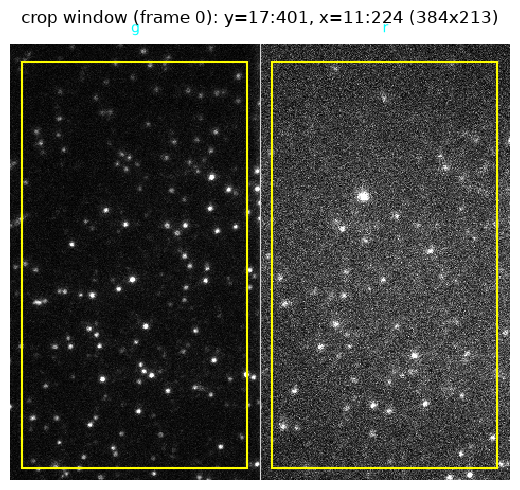

  [g] locs kept 126856/159069; total drift 5.83 px
  [r] locs kept 36474/44431; total drift 5.82 px
  crop window: CropWindow(y0=17, x0=11, height=384, width=213; margins: top=17, bottom=11, left=11, right=12)
  corrected stack: MultiImageStack(C=2, T=2000, H=384, W=213, channels=['g', 'r'], ref='g')


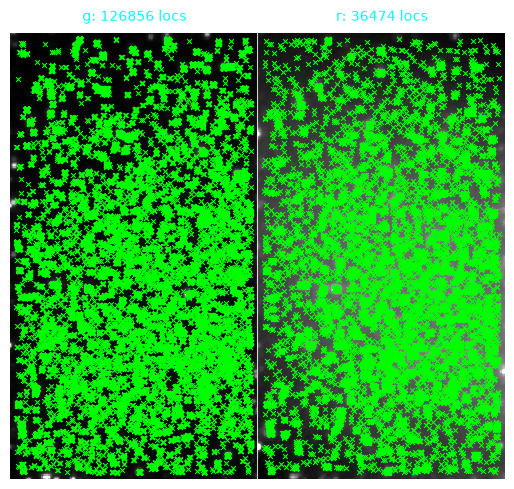

In [13]:
import smlm.multiplex as mp

DRIFT_INTERPOLATION_ORDER = 1  # 1 = linear interpolation.
# Per-edge values: int (all sides), {side: px}, or (top, bottom, left, right).
DRIFT_PAD_PX = dict(top=4, bottom=4, left=4, right=4)
EDGE_TRIM_PX = dict(top=7, bottom=7, left=7, right=7)
LOC_EDGE = 5                   # Reject localizations closer than this to the crop edge.

window = mp.drift_crop_window(
    multiDrift, multiStackAnalysis.shape[-2:],
    pad=DRIFT_PAD_PX, extra_trim=EDGE_TRIM_PX,
)
print(window)
print('per-channel drift needs:', window.requirements)

fig = mp.plot_multichannel_crop(multiStackAnalysis, y=window.y, x=window.x,
                                frame=0)
plt.show()

multiStackCorr, multiLocsCorr = mp.correct_multi(
    multiStackAnalysis,
    multiLocs,
    multiDrift,
    window=window,
    edge=LOC_EDGE,
    interpolation_order=DRIFT_INTERPOLATION_ORDER,
    verbose=True,
)

fig = plot_multichannel_localizations(multiStackCorr, multiLocsCorr)
plt.show()


## Emitters and traces per channel

Cluster emitters inside each channel, then extract traces with a per-channel choice of centre source and background-mask source. A channel not listed in `centers_from` gets no trace.

连接得到 5373 个 emitter
MinDurationFilter: 保留 1751 / 5373
FirstFrameFilter: 保留 1751 / 1751
EccentricityFilter: 保留 1421 / 1751
  [g] kept 1421 emitters from 5373 linked (126856 localizations)
连接得到 8969 个 emitter
合并后剩余 5652 / 8969 个 emitter
MinDurationFilter: 保留 422 / 5652
FirstFrameFilter: 保留 422 / 422
EccentricityFilter: 保留 370 / 422
  [r] kept 370 emitters from 5652 linked (36474 localizations)


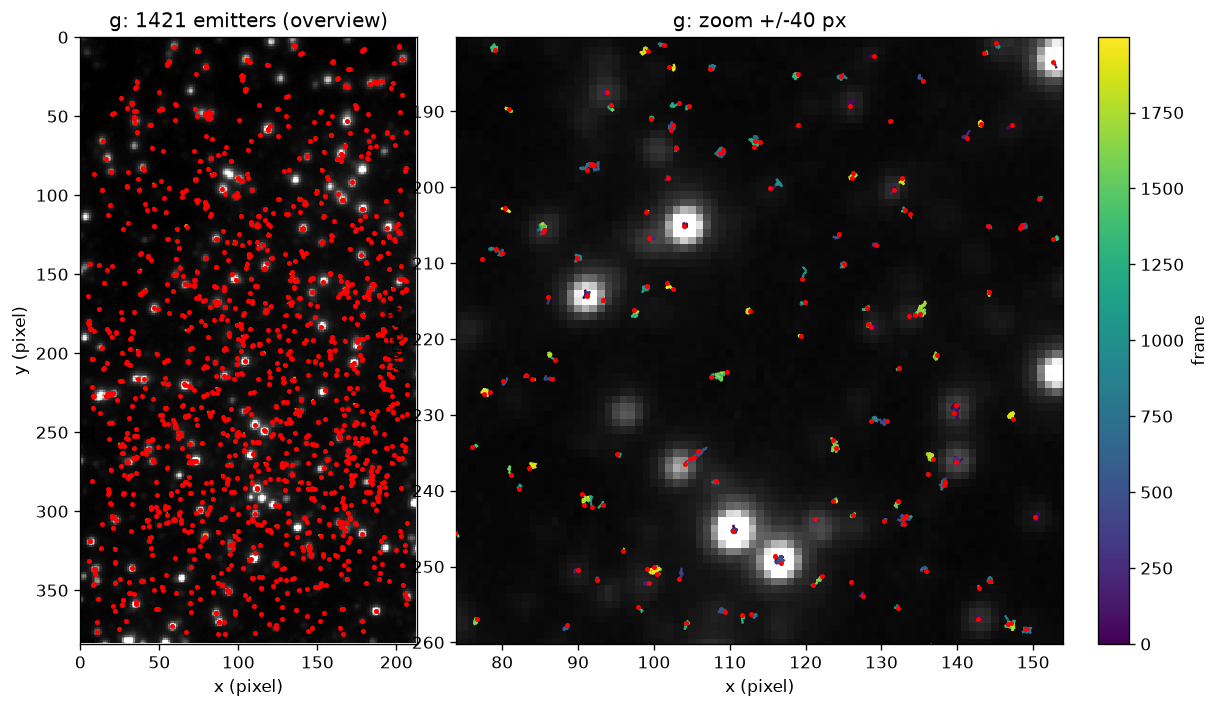

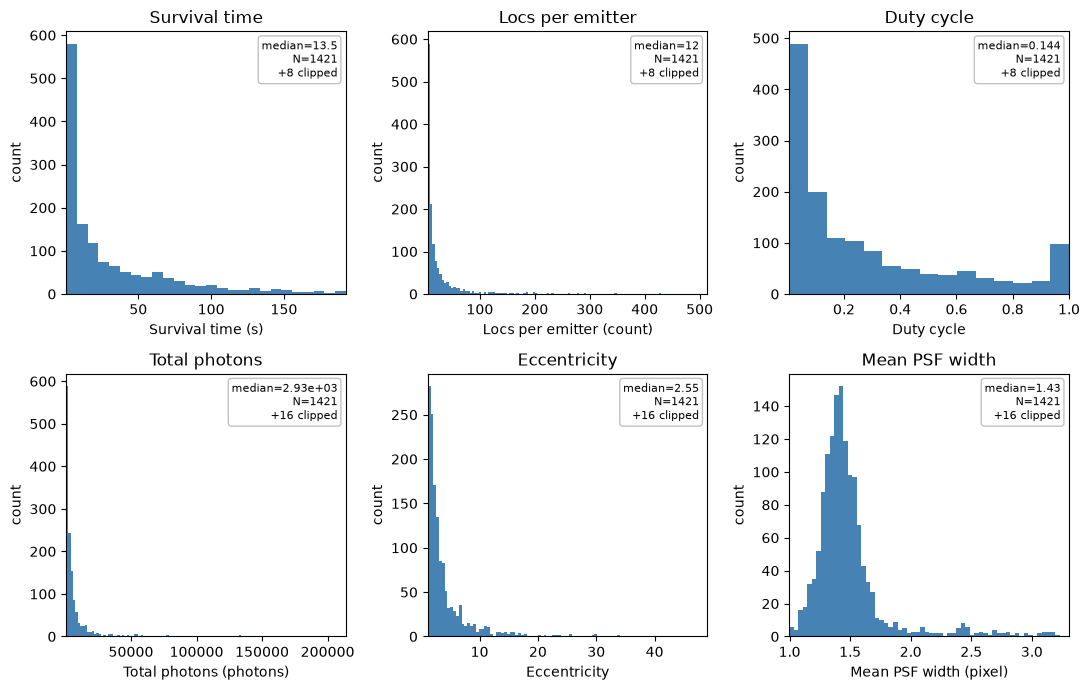

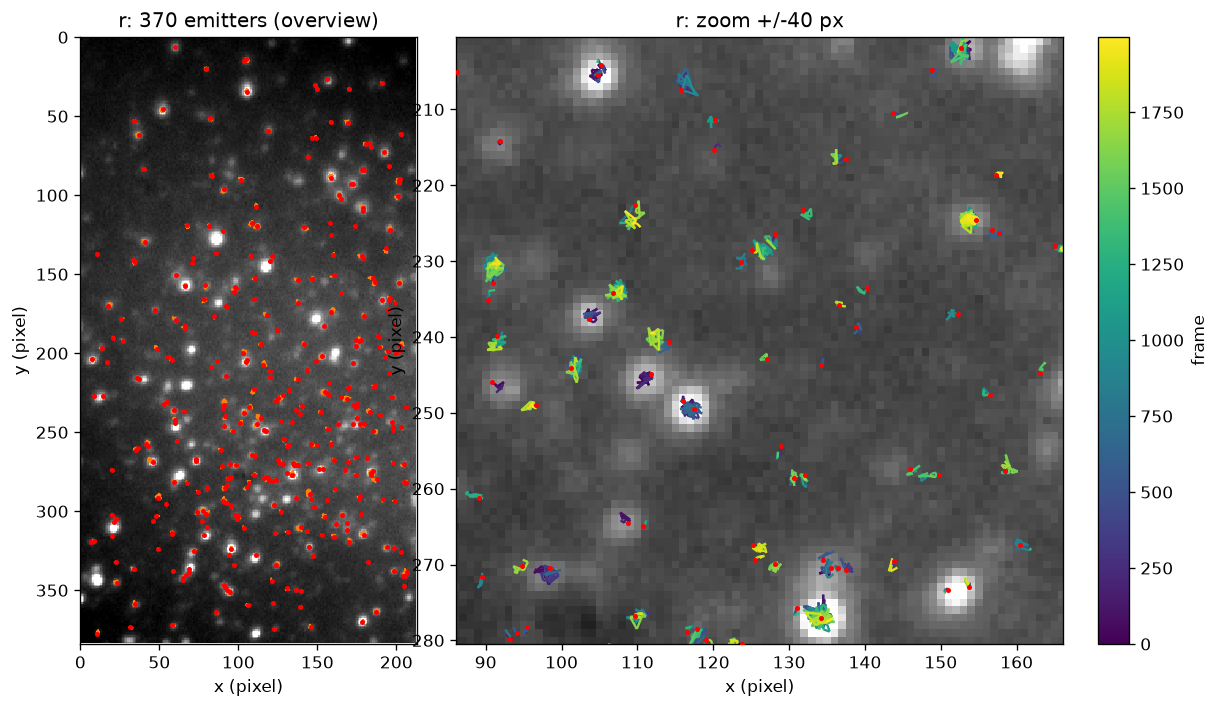

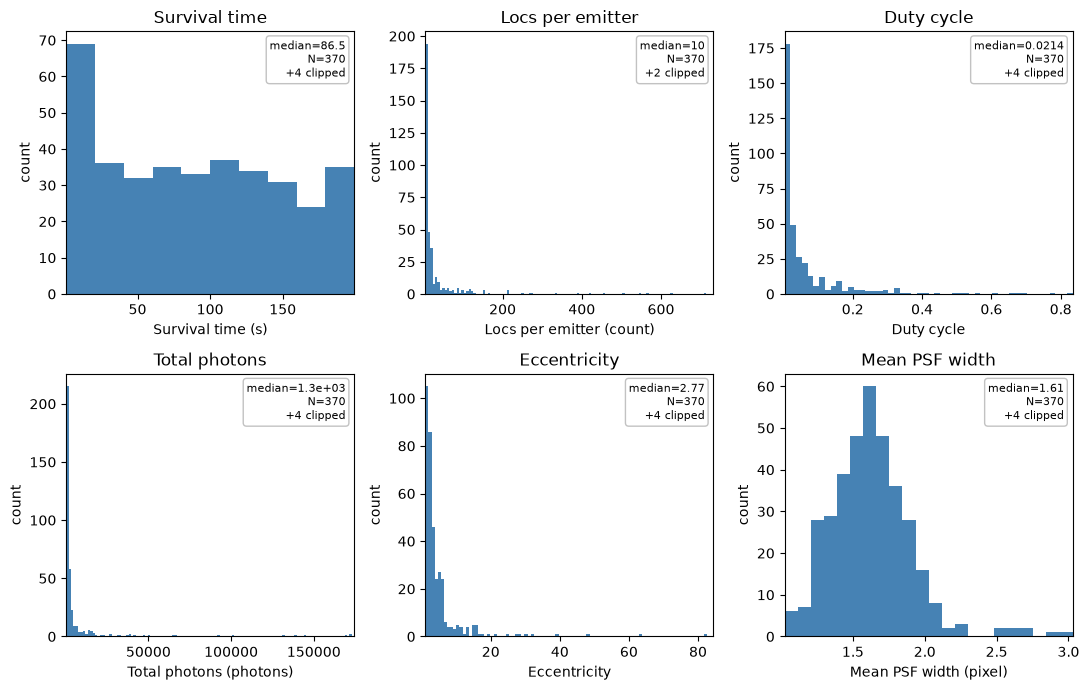

In [14]:
import smlm.multiplex as mp

# 两个通道的角色不同 -> 过滤参数必须分开给:
#   g: 只用来提供**挖洞位置**(背景环里邻居的核心要挖掉)。少认一个就少挖一个洞,
#      附近所有 trace 的背景都偏高; 而误挖一个洞只损失几十个环像素。
#      => 宁可多留: 关掉偏心剔除, 合并半径收紧(别把邻居并成一个中心)
#   r: 提供孔径中心与最终 trace, 稀疏, 要高质量
#      => 严格: 轨迹够长才要, 偏心剔除打开
LINK_KW = dict(search_radius=0.6, max_gap=1000, motion='static',
               first_frame_range=(0, multiStackCorr.n_frames - 1),
               ecc_p=1e-3)
LINK_KW_BY_CHANNEL = {
    # r_merge 只在 do_merge=True 时生效
    'g': dict(search_radius=0.9, min_frames=5, ecc_min=None, do_merge=False),
    'r': dict(min_frames=5, ecc_min=1.5, do_merge=True),
}

multiEmitters, multiAll = mp.analyze_multichannel_emitters(
    multiStackCorr, multiLocsCorr,
    n_frames=multiStackCorr.n_frames,
    link_kw=LINK_KW, link_kw_per_channel=LINK_KW_BY_CHANNEL,
    return_all=True, verbose=True,
)
{channel: {'linked': len(multiAll[channel]),
           'kept': len(emitters),
           'kept_pct': round(100 * len(emitters) / max(len(multiAll[channel]), 1)),
           'median_locs': float(np.median([e.n_locs for e in emitters])) if emitters else 0.0}
 for channel, emitters in multiEmitters.items()}

# ---- display: trajectories over a 200-frame mean image, plus a zoomed view ----
from smlm.emitter import collect_statistics
from smlm.viz import plot_trajectories, plot_emitter_stats

PREVIEW_FRAMES = slice(0, 200)
ZOOM_HALF = 40          # px around the emitters' median centre

for channel, emitters in multiEmitters.items():
    if not emitters:
        print(f'{channel}: no emitters')
        continue
    channel_data = multiStackCorr.channel(channel).data
    background = channel_data[PREVIEW_FRAMES].mean(axis=0, dtype=np.float32)

    centres_yx = np.array([[e.centroid[1], e.centroid[0]] for e in emitters])
    cy, cx = np.median(centres_yx, axis=0)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6), dpi=120)
    plot_trajectories(background, emitters, ax=axes[0], mark_start=True,
                      color_by='none', linewidth=0.8)
    axes[0].set_title(f'{channel}: {len(emitters)} emitters (overview)')

    plot_trajectories(background, emitters, ax=axes[1], mark_start=True,
                      linewidth=1.4)
    axes[1].set_xlim(cx - ZOOM_HALF, cx + ZOOM_HALF)
    axes[1].set_ylim(cy + ZOOM_HALF, cy - ZOOM_HALF)
    axes[1].set_title(f'{channel}: zoom +/-{ZOOM_HALF} px')
    plt.show()

    plot_emitter_stats(collect_statistics(emitters, multiLocsCorr[channel],
                                          EXPOSURE_S, 0))
    plt.show()


In [15]:
import smlm.fret as fr
import smlm.trace as tr

WAVELEN_NM, NA = 640.0, 1.4
PSF_SIGMA_PX = 0.2165 * WAVELEN_NM / NA / float(image.pixel_size)

# aperture centres come from one physical channel; each channel masks its own
# background ring with its own emitters
TRACE_CENTERS_FROM = {'r': 'r', 'g': 'r'}
TRACE_MASK_FROM = {'r': 'r', 'g': 'g'}

multiTraces = mp.extract_multichannel_traces(
    multiStackCorr, multiEmitters,
    centers_from=TRACE_CENTERS_FROM,
    mask_from=TRACE_MASK_FROM,
    sigma=PSF_SIGMA_PX,          # 显式 PSF σ (px); matched 核要用, 不从 locs 估
    mode='matched', k_sigma=2.0,
    n_frames=multiStackCorr.n_frames,
    verbose=True,
)

{channel: {'n_traces': len(traces),
           'n_frames': traces[0].frames.size if traces else 0}
 for channel, traces in multiTraces.items()}


<string>:12: RuntimeWarning: 分析窗口比标定点覆盖大 14.9 px; 当前是 order 1(仿射), 外推精确, 可忽略。   r 超出 x 9.1 / y 14.9 px


  [r] 370 条 trace, 阶段: ApertureRaw -> AnnulusRing -> IntensityFromRawBg -> PoissonSNR
  [r]   ApertureRaw: matched, r=2σ, [2, 7] px
  [r]   AnnulusRing: ring +2..+6 px, excl 2, clip 3x3
  [r]   IntensityFromRawBg: intensity = raw - bg*sw/sw2
  [r]   PoissonSNR: snr = total / sqrt(total + area_eff*bg_std^2)
  [r]   半径 2~2 px (中位 2), σ 中位 0.93 px
  [r]   背景中心 370 个(外部屏蔽), 环像素中位 143, 邻居中位 2
  [r] centres from 'r', background masked by 'r': 370 traces
  [g] 370 条 trace, 阶段: ApertureRaw -> AnnulusRing -> IntensityFromRawBg -> PoissonSNR
  [g]   ApertureRaw: matched, r=2σ, [2, 7] px
  [g]   AnnulusRing: ring +2..+6 px, excl 2, clip 3x3
  [g]   IntensityFromRawBg: intensity = raw - bg*sw/sw2
  [g]   PoissonSNR: snr = total / sqrt(total + area_eff*bg_std^2)
  [g]   半径 2~2 px (中位 2), σ 中位 0.93 px
  [g]   背景中心 1421 个(外部屏蔽), 环像素中位 120, 邻居中位 8
  [g] centres from 'r', background masked by 'g': 370 traces


{'r': {'n_traces': 370, 'n_frames': 2000},
 'g': {'n_traces': 370, 'n_frames': 2000}}

### 双通道 trace 概览

**颜色 = 通道，亮度 = 字段** —— 每个子图里叠加所有选中通道，同一个通道的不同属性
用 alpha 区分（组内第一个字段最亮，后面的依次变暗），所以颜色永远不会被属性抢走。

`groups` 决定有哪些子图，语义与单通道的 `plot_trace_fields` 完全一致。

**背景用 `bg_flux` 而不是 `bg`**：`bg` 是逐像素的（ADU/px），比 `raw` 小两个量级；
`bg_flux` 是把环背景折算进信号核之后的**总量**，与 `raw` / `intensity` 同单位
（`intensity = raw − bg_flux`），画在一起才看得出扣了多少。

对比要点：
- 受体（红）亮、供体（绿）暗 → 有 FRET；两者同时亮说明没有能量转移
- 受体某时刻掉下去（光漂白）后，供体应同时**跳起来**（去淬灭）
- 供体一直暗而受体一直亮，可能只是受体被直接激发，不是真的 FRET 对


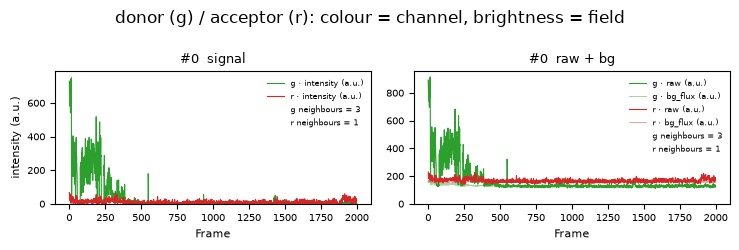

In [16]:
import matplotlib.pyplot as plt

fig = mp.plot_channel_traces(
    multiTraces,
    channels=('g', 'r'),                       # 要叠加的通道 (顺序 = 叠放顺序)
    colors={'g': 'tab:green', 'r': 'tab:red'}, # 颜色只用来区分通道
    groups={
        'signal':   dict(fields=('intensity',)),          # 第 1 列: 信号
        'raw + bg': dict(fields=('raw', 'bg_flux')),      # 第 2 列: raw + 核内总背景(更暗)
    },
    indices=range(1),
    scalars=('neighbours'),                       # 单个数 -> 图例, 每个通道一份
    title='donor (g) / acceptor (r): colour = channel, brightness = field')
plt.show()

In [ ]:
# ===================== 临时: 单通道式 emitter 检查 =====================
# 目的: **红光定位给的位置, 在绿光通道里到底有没有分子？**
#   - 窗口中心 = multiTraces['g'][i] 里存的 x/y, 也就是当时积分用的孔径中心
#   - 叠加的 x = 该分子的红光定位点 (经配准映射到绿通道坐标系)
#   - 右侧曲线 = 该分子的**绿光 trace**, 随视频帧同步
from dataclasses import replace

from smlm.viz import preview_emitters

GREEN = multiStackCorr.channel('g')
# 与 extract_multichannel_traces 内部用的是同一个 geometry
GEOM = multiStackCorr.geometry(check_coverage=False)

# 红光定位点 -> 绿通道坐标 (叠加用)
xy_r = np.column_stack([multiLocsCorr['r'].x, multiLocsCorr['r'].y])
xy_r_in_g = mp.map_channel_xy(xy_r, GEOM, 'r', 'g')
locs_r_in_g = replace(multiLocsCorr['r'],
                      x=xy_r_in_g[:, 0], y=xy_r_in_g[:, 1])

# 窗口中心直接取 trace 里存的坐标, 保证与积分时用的完全一致
assert len(multiEmitters['r']) == len(multiTraces['g']), '中心与 trace 没对齐'
red_at_green = [
    replace(e, x=np.full(e.n_locs, multiTraces['g'][i]['x']),
               y=np.full(e.n_locs, multiTraces['g'][i]['y']))
    for i, e in enumerate(multiEmitters['r'])]

# 顺手核对: 配准映射出来的中心 与 trace 用的中心 是否一致
cen_r = np.array([[e.centroid[1], e.centroid[0]] for e in multiEmitters['r']])
cen_g = mp.map_channel_xy(cen_r[:, ::-1], GEOM, 'r', 'g')[:, ::-1]
used = np.array([[t['y'], t['x']] for t in multiTraces['g']])
print(f'中心对齐: 最大偏差 {np.abs(cen_g - used).max():.2e} px')

CHECK = [50]         # 想抽查哪几个就换成列表, 例如 [3, 17, 42]
print(f'检查 {len(list(CHECK))} 个: 绿光通道 + 红光定位坐标 + 绿光 trace')

preview_emitters(
    GREEN, multiTraces['g'], red_at_green, locs_r_in_g,
    indices=CHECK, half=12, frames=slice(0, 1500),
    ncols=2, width=440,
    exposure_time=EXPOSURE_S, speed=10,
)

## 挑选合格的 trace pair

判据在 `smlm/fret/pairs.py`，只做**污染判据**，与 E 的大小无关：

| 级 | 判据 | 含义 |
|---|---|---|
| `event` | `find_step` 找不到"红降 + 绿升"台阶 | 没有 FRET 事件 |
| `red` | 台阶前 **10 帧**的 `intensity` 中位 ≤ 150 | 受体在"漂白"之前根本没在发光（用全程最大值会被一个热像素骗过） |
| `flags` | `EventSpec` 物理门限 | 台阶前受体在亮、台阶后真灭、绿升显著且持续、去淬灭后供体在亮 |
| `spread` | pre 窗绿光离散度 ≤ 2.5 × 光子噪声 | 被淬灭的供体是**恒定暗态**；邻居闪烁会把离散度顶上去 |
| `attr` | pre 窗孔径内绿光分子数 ≤ 1 | 直接检验"绿光密、亮度不可靠"；按 0.9 px 去重，避免一个分子被拆成两条 |
| `neigh` | 绿光背景环内邻居数（默认不限，只报数） | 环背景可信度 |
| `after` | 红光灭后 `p95` 不再亮 | 孔径里还有第二个受体 |

**刻意没有** `I_D^pre ≤ f·I_D^post`：那个比值就是 `1 − E`，拿它当质量门限等于按 E 筛
分子，会让后面报出的 E 分布有偏。


In [17]:
# 判据见 smlm/fret/pairs.py。这里**不**包含 I_D^pre/I_D^post 的比值门限:
# 那个比值就是 1−E, 拿它筛等于按 E 筛分子, 会让后面的 E 分布有偏。
PAIR_CRIT = fr.PairCriteria(
    red_min=100.0,      # 台阶前 red_win 帧的中位亮度必须高于它
    red_win=10,         # 往前数 10 帧
    lag_max=10,         # 绿光去淬灭允许滞后 (帧)
    pre_win=60,         # "洁净度"检查窗 (帧)
    k_spread=2.5,       # pre 窗离散度 <= 2.5 × 光子噪声
    attr_scale=0.8,     # 归属半径 = 0.8 × 孔径半径
    attr_dup=0.9,       # 相距 < 0.9 px 的绿光中心算同一个物理分子
    max_n_pre=1,        # pre 窗内孔径里最多 1 个绿光分子
)

pairRecords, pairStats = fr.select_pairs(
    multiTraces['r'], multiTraces['g'],
    emitters_d=multiEmitters['g'],     # 绿光自己的 emitter: 孔径里有没有别人
    crit=PAIR_CRIT, verbose=True,
)


PairCriteria(漂白前 10 帧中位 ≥100, lag≤10 帧, pre 窗 60 帧 离散度≤2.5σ, 孔径 0.8×r 内 ≤1 个, 环内邻居 不限, 灭后 占空比≤20%)
候选 trace 对: 370
  1. 没找到红降+绿升台阶      :    252
  2. 漂白前窗口不够亮        :     17  (-235)
  3. 物理门限不合格         :     10  (-7)
  4. pre 窗绿光不平稳      :      9  (-1)
  5. 孔径内绿光分子 > 1     :      9  (-0)
  6. 红光灭后又亮          :      4  (-5)   <-- 合格 (4)
  原因分布 (可重叠): 没找到红降+绿升台阶 118, 漂白前窗口不够亮 235, 物理门限不合格 233, pre 窗绿光不平稳 25, 红光灭后又亮 88
  物理门限明细 (EventSpec: sw=4, 长窗 20, lag≤10; 红降>4σ_A, 绿升>2σ_D, 持续>2σ_D, 去淬灭后>3σ_D, ΔI_D>150 photon):
    pre_a   台阶前受体在发光           156 条
    off_a   台阶后真的灭掉              6 条
    red     红降显著               212 条
    grn     绿升显著                96 条
    hold    绿升持续               185 条
    post_d  去淬灭后供体在发光           98 条
    drop_d  ΔI_D 绝对幅度          216 条   (未纳入 require, 仅统计)

合格对的关键量 (中位):
  漂白前 10 帧 148   I_A^max 376   pre 离散度 1.26σ   pre 电平 2.3σ   噪声模型/实测 2.4×
  I_A^pre 142  I_D^pre 25  I_D^post 185  lag 5 帧
  孔径内绿光分子总能找到: [1, 0, 0, 3]   (下标 = 个数, 值 = 条数)
  其中 pre 窗在发光:

否决样例: 366 条


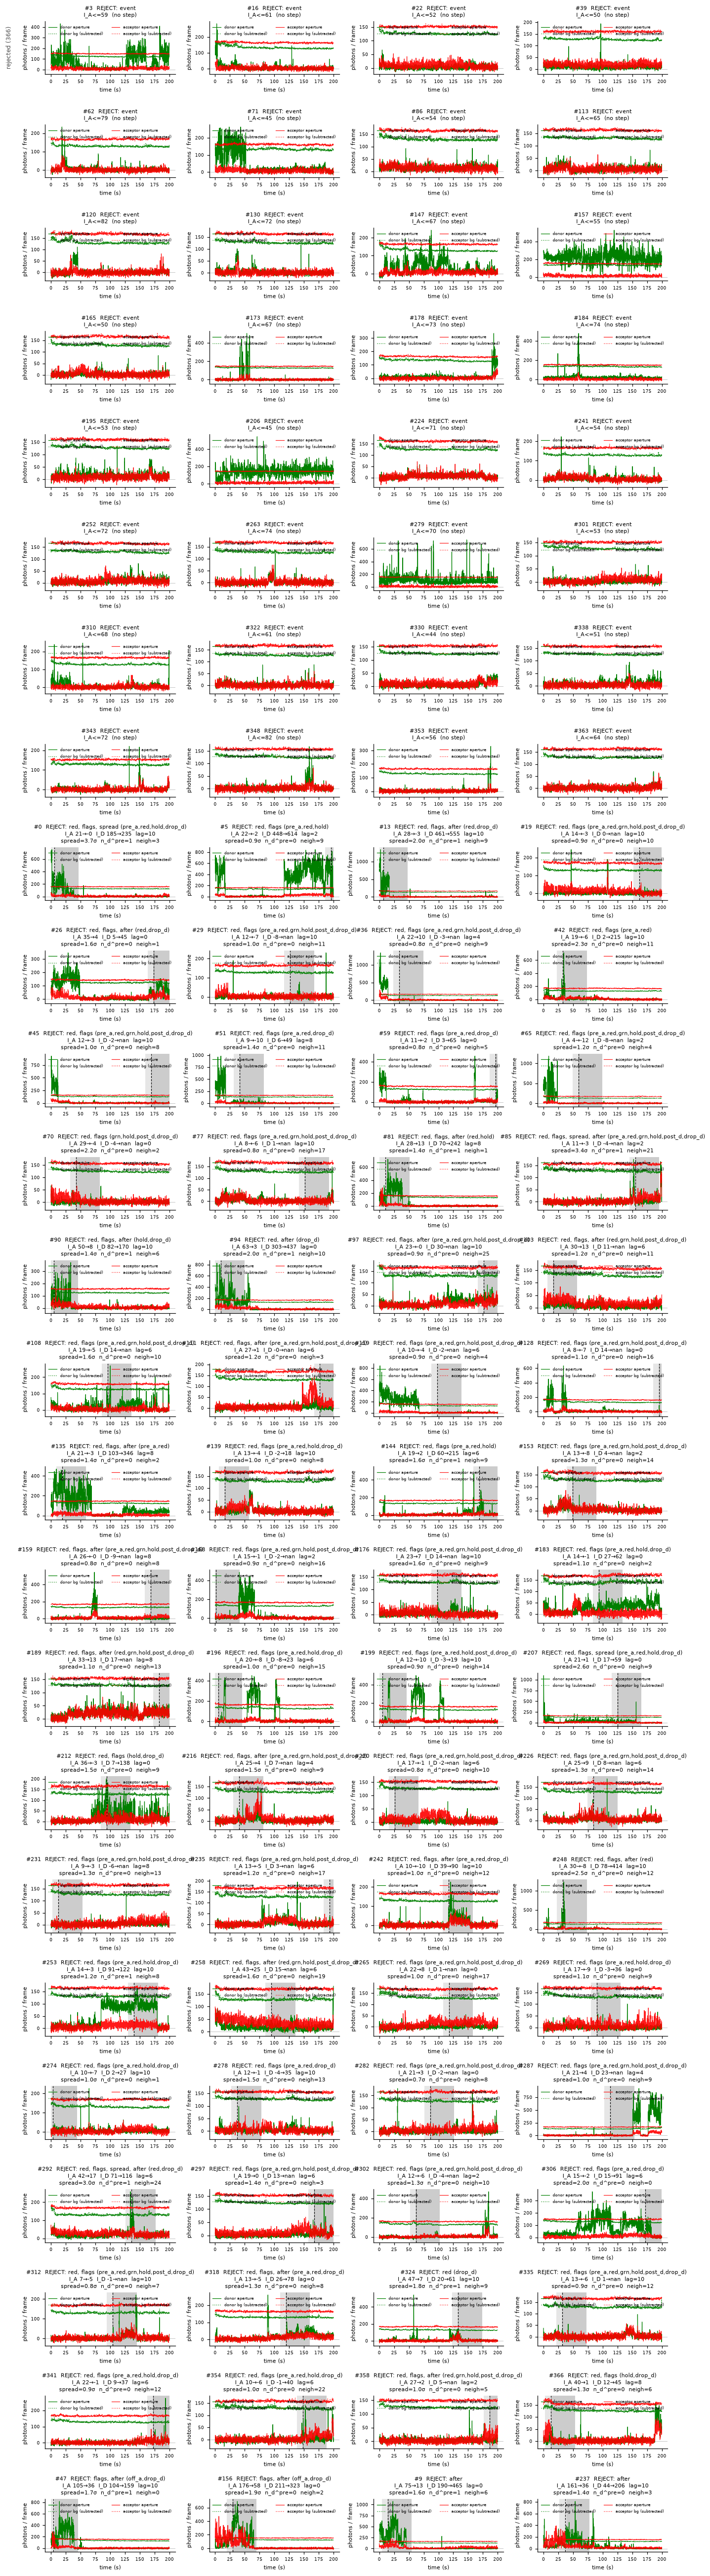

In [18]:
# 否决样例: 标题里写明因为什么被否 (物理门限会具体到哪一条子判据)
# ONLY = ('flags',) 就只看"物理门限不合格"那批; None = 看所有否决原因
ONLY = None
rejPairs = [r for r in pairRecords
            if not r.keep and (ONLY is None or any(k in r.reasons for k in ONLY))]
print(f'否决样例: {len(rejPairs)} 条' + (f'  (只看 {ONLY})' if ONLY else ''))

fig = fr.viz.plot_pair_gallery(rejPairs, multiTraces['r'], multiTraces['g'],
                               which='rejected', n=100, ncols=4,
                               ex_time=EXPOSURE_S)
plt.show()


In [ ]:
# 合格对上算 E。γ 先固定, α/β 仍从这批事件估 (它们只影响分子的绝对标度)
pairEvents = [r.event for r in pairRecords if r.keep]

GAMMA_FIXED = 1.1          # 通道增益比, 先固定; 之后用更多事件标定

fretCal = fr.calibrate(pairEvents, traces_a=multiTraces['r'],
                       traces_d=multiTraces['g'])
print(f'\n[!] γ 固定为 {GAMMA_FIXED} (这批数据自己估到 {fretCal.gamma:.3f})')
fretCal.gamma = float(GAMMA_FIXED)
fretCal.report()

fretResults, fretStats = fr.fret_efficiency(
    pairEvents, multiTraces['r'], multiTraces['g'], fretCal,
    t_bleach=lambda j: j * EXPOSURE_S,
)
fr.attach_efficiency(pairRecords, fretResults)

print(f'合格对 {pairStats["n_keep"]} -> 事件 {len(pairEvents)} '
      f'-> 算出 E 的 {len(fretResults)}')
if fretResults:
    e = np.array([r.E for r in fretResults])
    ed = np.array([r.E_don for r in fretResults])
    print(f'E      中位 {np.median(e):.3f}   p16~p84 '
          f'{np.percentile(e, 16):.3f}~{np.percentile(e, 84):.3f}   '
          f'n={e.size}')
    print(f'E_don  中位 {np.median(ed):.3f}   p16~p84 '
          f'{np.percentile(ed, 16):.3f}~{np.percentile(ed, 84):.3f}   '
          f'(不用 γ, 只做交叉检验)')

fig, ax = plt.subplots(figsize=(4.6, 4.0), dpi=110)
fr.viz.plot_gamma(pairEvents, fretCal, ax=ax)
plt.show()


In [ ]:
# E 分布 + E vs 受体亮度 (检查暗分子有没有系统性偏差)
# 左: 紫直方图 = E, 灰阶梯 = E_don (不用 γ/α/β 的交叉检验); E>0.95 的比例是**下界**
# 右: 黑点 = 按亮度分位数分箱后的中位 ± p16~p84
if fretResults:
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4), dpi=110)
    fr.viz.plot_efficiency(fretResults, ax=axes[0])
    fr.viz.plot_efficiency_vs_brightness(fretResults, ax=axes[1], key='IA_pre')
    fig.tight_layout()
    plt.show()
else:
    print('没有算出 E: 先看上一格的否决原因报表')


In [ ]:
# E < 0.85 的合格对到底长什么样
# 看点: I_D^pre 是不是"稳定的大值"(真低 FRET), 还是被邻居闪烁/背景过扣搞出来的
E_CUT = 0.85
keptPairs = [r for r in pairRecords if r.keep]
lowPairs = [r for r in keptPairs if np.isfinite(r.E) and r.E < E_CUT]
print(f'E < {E_CUT}: {len(lowPairs)} / {len(keptPairs)} 条合格对')

if lowPairs:
    import pandas as pd
    by_id = {x.emitter_id: x for x in fretResults}
    rows = []
    for rec in sorted(lowPairs, key=lambda r: r.E):
        ev, res = rec.event, by_id.get(rec.emitter_id)
        rows.append({
            'id': rec.emitter_id,
            'E': rec.E,
            'E_don': np.nan if res is None else res.E_don,
            'I_A^pre': ev.IA_pre,
            'I_A_pre10': rec.IA_pre_win,
            'I_D^pre': ev.ID_pre,
            'I_D^post': ev.ID_post,
            'D_pre/post': ev.ID_pre / ev.ID_post,
            'snr_A': np.nan if res is None else res.snr_A,
            'lag': ev.lag,
            'n_pre': -1 if res is None else res.n_pre,
            'n_on': -1 if res is None else res.n_on,
            'spread': rec.spread,
            'n_d_pre': rec.n_d_pre,
            'n_in_ap': rec.n_in_ap,
            'd_nea_px': rec.d_nearest,
        })
    print(pd.DataFrame(rows).to_string(index=False,
                                       float_format='{:.3g}'.format))
    fr.viz.plot_pair_gallery(lowPairs, multiTraces['r'], multiTraces['g'],
                             which='kept', n=len(lowPairs), ncols=4,
                             ex_time=EXPOSURE_S)
    plt.show()
else:
    print('没有低于该阈值的合格对')


## 落盘: 成品目录

<kbd>DATA_FILE</kbd> 同目录下的 `<名字>_fret/`:

| 文件 | 内容 |
|---|---|
| `fret.csv` | 逐分子 E 与 γ/α/β —— 下游统计只读它 |
| `E_distribution.png` | E 分布 + E vs 受体亮度 + E vs $I_D^{pre}$ |
| `good_traces_all.png` | 通过判据的 trace 全览 |
| `traces_all.csv` | 全部 trace (一行 = 一分子一帧), 可 `fr.load_traces_csv` 读回 |
| `good_traces.csv` | 通过判据的那些 trace (同格式) |


In [ ]:
# 落盘: <sif 同目录>/<名字>_fret/  (目录里五个文件的名字见 fr.FILES)
OUT_DIR = DATA_FILE.with_name(DATA_FILE.stem + '_fret')

fretBundle = fr.save_bundle(
    OUT_DIR,
    records=pairRecords,               # 全部候选(含否决), 里面带 keep
    results=fretResults,               # 算出 E 的那些
    traces_d=multiTraces['g'],         # 供体 = 绿
    traces_a=multiTraces['r'],         # 受体 = 红
    cal=fretCal,
    ex_time=EXPOSURE_S,
    title=DATA_FILE.stem,
)

# 读回示例:
#   t = fr.load_traces_csv(OUT_DIR / 'good_traces.csv')
#   t['emitter_id'], t['I_acceptor'].shape
